# E4 — Descriptor-space geometry

## Objective

Quantify how the lytic protein universe is organized in explicitly interpretable descriptor space.

E4 does **not** estimate new descriptors. It consumes the two frozen descriptor blocks generated upstream:

- **E2 composition/complexity descriptors**
- **E3 physicochemical/biophysical descriptors**

Six geometry views are compared:

1. `E2_all`
2. `E3_all`
3. `E2_E3_all`
4. `E2_important`
5. `E3_important`
6. `E2_E3_important`

## Important multivariate-data rule

E2 legitimately contains a small number of undefined ratio values when the denominator is zero. Those
values were validly handled feature-wise in the univariate E2 analysis, but PCA, UMAP, Euclidean
distances, and kNN require a complete numeric matrix.

E4 therefore **does not impute those undefined ratios and does not delete proteins**. Instead, any
descriptor containing non-finite/missing values is excluded from multivariate geometry and recorded in
`roxy_geometry_feature_eligibility.tsv`. Constant descriptors are also excluded because they carry no
geometric information.

The complete frozen E2 and E3 feature contracts remain unchanged; E4 only defines a geometry-eligible
subset for multivariate analysis.

## Important-feature selection

Within each geometry-eligible stage, feature importance is based on effect-size distributions:

- global score = median |Cliff's delta| across `P_core vs N_easy`, `P_core vs N_hard`,
  and `P_core vs N_mixed`;
- subtype score = median |Cliff's delta| across Endolysin, Depolymerase, and VAL pairwise contrasts;
- stage score = max(global score, subtype score).

Features at or above the stage-specific Q75 of the score distribution are retained as `important`.

## Geometry

For every feature view:

- standardization is fitted on the complete frozen E0 universe;
- PCA is fitted on the complete universe with IncrementalPCA;
- UMAP is used only for visualization on a fixed shared visualization sample;
- quantitative geometry is measured in the **original standardized descriptor space**, never in UMAP;
- the same balanced sequence IDs are reused across all feature views.

Quantitative scopes:

- `global_three_state`: P_core / N_easy / N_hard
- `global_binary`: P_core / N_mixed
- `clean_subtypes`: Endolysin / Depolymerase / VAL

Repeated balanced subsampling is used for silhouette, centroid separation, within-group dispersion,
and neighborhood composition.


In [1]:
from pathlib import Path
import hashlib
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

try:
    import umap
except ImportError as exc:
    raise ImportError(
        "E4 requires umap-learn. Install it in the active environment "
        "with: pip install umap-learn"
    ) from exc

from IPython.display import display

sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.0,
)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)

RANDOM_SEED = 42
PCA_COMPONENTS = 10
PCA_CHUNK_SIZE = 20_000

UMAP_N_NEIGHBORS = 30
UMAP_MIN_DIST = 0.20

NEIGHBOR_K_VALUES = [10, 25, 50]

GLOBAL_METRIC_REPEATS = 10
GLOBAL_THREE_STATE_N_PER_GROUP = 2_000
GLOBAL_BINARY_N_PER_GROUP = 4_000

SUBTYPE_METRIC_REPEATS = 20
SUBTYPE_N_PER_GROUP = 200

GLOBAL_VIZ_N_PER_GROUP = 3_000
SUBTYPE_VIZ_N_PER_GROUP = 200

## 1. Paths and frozen inputs

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = (
    PROJECT_ROOT
    / "EDA_results"
    / "E0"
    / "phagelytic_eda_universe.csv"
)

E2_DIR = PROJECT_ROOT / "EDA_results" / "E2"
E3_DIR = PROJECT_ROOT / "EDA_results" / "E3"

E2_DESCRIPTOR_PATH = E2_DIR / "roxy_sequence_composition.parquet"
E2_FEATURE_MANIFEST_PATH = E2_DIR / "analysis_feature_manifest.tsv"
E2_MISSINGNESS_PATH = E2_DIR / "composition_missingness.tsv"
E2_AAC_GLOBAL_PATH = E2_DIR / "aac_effects_global.tsv"
E2_AAC_SUBTYPE_PATH = E2_DIR / "aac_effects_subtypes.tsv"
E2_COMPOSITION_GLOBAL_PATH = E2_DIR / "composition_effects_global.tsv"
E2_COMPOSITION_SUBTYPE_PATH = E2_DIR / "composition_effects_subtypes.tsv"

E3_DESCRIPTOR_PATH = E3_DIR / "physicochemical_descriptors.parquet"
E3_FEATURE_MANIFEST_PATH = E3_DIR / "physicochemical_feature_manifest.tsv"
E3_GLOBAL_PATH = E3_DIR / "global_descriptor_effects.tsv"
E3_SUBTYPE_PATH = E3_DIR / "subtype_descriptor_effects.tsv"

RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E4"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_ELIGIBILITY_PATH = RESULT_DIR / "roxy_geometry_feature_eligibility.tsv"
FEATURE_SETS_PATH = RESULT_DIR / "roxy_geometry_feature_sets.tsv"
IMPORTANCE_PATH = RESULT_DIR / "roxy_geometry_feature_importance.tsv"
SAMPLE_MANIFEST_PATH = RESULT_DIR / "roxy_geometry_samples.tsv"

PCA_COORDINATES_PATH = RESULT_DIR / "roxy_pca_coordinates.tsv"
UMAP_COORDINATES_PATH = RESULT_DIR / "roxy_umap_coordinates.tsv"
PCA_VARIANCE_PATH = RESULT_DIR / "roxy_pca_explained_variance.tsv"
PCA_LOADINGS_PATH = RESULT_DIR / "roxy_pca_loadings.tsv"

GEOMETRY_REPEATS_PATH = RESULT_DIR / "roxy_geometry_repeats.tsv"
GEOMETRY_SUMMARY_PATH = RESULT_DIR / "roxy_geometry_summary.tsv"

NEIGHBORHOOD_REPEATS_PATH = RESULT_DIR / "roxy_neighborhood_repeats.tsv"
NEIGHBORHOODS_PATH = RESULT_DIR / "roxy_neighborhoods.tsv"

METADATA_PATH = RESULT_DIR / "roxy_geometry_metadata.json"

required_inputs = [
    E0_PATH,
    E2_DESCRIPTOR_PATH,
    E2_FEATURE_MANIFEST_PATH,
    E2_MISSINGNESS_PATH,
    E2_AAC_GLOBAL_PATH,
    E2_AAC_SUBTYPE_PATH,
    E2_COMPOSITION_GLOBAL_PATH,
    E2_COMPOSITION_SUBTYPE_PATH,
    E3_DESCRIPTOR_PATH,
    E3_FEATURE_MANIFEST_PATH,
    E3_GLOBAL_PATH,
    E3_SUBTYPE_PATH,
]

missing_inputs = [
    path
    for path in required_inputs
    if not path.is_file()
]

if missing_inputs:
    raise FileNotFoundError(
        "Missing frozen E4 input(s):\n"
        + "\n".join(str(path) for path in missing_inputs)
    )

print(f"Project root : {PROJECT_ROOT}")
print(f"E4 results   : {RESULT_DIR}")


Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
E4 results   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4


## 2. Load frozen E0 labels

In [3]:
e0 = pd.read_csv(
    E0_PATH,
    usecols=[
        "sequence_uid",
        "sequence_state",
        "clean_subtype",
    ],
    dtype={
        "sequence_uid": str,
        "sequence_state": str,
        "clean_subtype": str,
    },
    low_memory=False,
)

EXPECTED_ROWS = 442_329

assert len(e0) == EXPECTED_ROWS
assert e0["sequence_uid"].is_unique
assert e0["sequence_uid"].notna().all()


# ---------------------------------------------------------------------
# Binary global label
#
# Use pandas nullable string dtype instead of np.where(..., np.nan).
# This is robust under NumPy 2.x and preserves missing labels as pd.NA.
# ---------------------------------------------------------------------

e0["binary_label"] = pd.Series(
    pd.NA,
    index=e0.index,
    dtype="string",
)

e0.loc[
    e0["sequence_state"].eq("P_core"),
    "binary_label",
] = "P_core"

e0.loc[
    e0["sequence_state"].isin(
        ["N_easy", "N_hard"]
    ),
    "binary_label",
] = "N_mixed"


# ---------------------------------------------------------------------
# Clean subtype label
# ---------------------------------------------------------------------

CLEAN_SUBTYPES = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

e0["subtype_label"] = pd.Series(
    pd.NA,
    index=e0.index,
    dtype="string",
)

clean_subtype_mask = e0[
    "clean_subtype"
].isin(
    CLEAN_SUBTYPES
)

e0.loc[
    clean_subtype_mask,
    "subtype_label",
] = (
    e0.loc[
        clean_subtype_mask,
        "clean_subtype",
    ]
    .astype("string")
)


# ---------------------------------------------------------------------
# Audit
# ---------------------------------------------------------------------

assert (
    e0.loc[
        e0["sequence_state"].eq("P_core"),
        "binary_label",
    ]
    .eq("P_core")
    .all()
)

assert (
    e0.loc[
        e0["sequence_state"].isin(
            ["N_easy", "N_hard"]
        ),
        "binary_label",
    ]
    .eq("N_mixed")
    .all()
)

assert (
    e0.loc[
        ~e0["sequence_state"].isin(
            [
                "P_core",
                "N_easy",
                "N_hard",
            ]
        ),
        "binary_label",
    ]
    .isna()
    .all()
)

assert (
    e0.loc[
        clean_subtype_mask,
        "subtype_label",
    ]
    .notna()
    .all()
)

assert (
    e0.loc[
        ~clean_subtype_mask,
        "subtype_label",
    ]
    .isna()
    .all()
)


print(f"E0 rows: {len(e0):,}")

print()
print("Primary states")
display(
    e0["sequence_state"]
    .value_counts()
    .rename("n")
    .to_frame()
)

print()
print("Binary geometry labels")
display(
    e0["binary_label"]
    .value_counts(
        dropna=False
    )
    .rename("n")
    .to_frame()
)

print()
print("Clean subtype geometry labels")
display(
    e0["subtype_label"]
    .value_counts(
        dropna=False
    )
    .rename("n")
    .to_frame()
)


E0 rows: 442,329

Primary states


,n
sequence_state,
U_explicit,228075
U_other_unresolved,132145
N_easy,54711
P_core,11867
challenge_ambiguous_structural,10885
N_hard,4327
challenge_lytic_related,319



Binary geometry labels


,n
binary_label,
<NA>,371424
N_mixed,59038
P_core,11867



Clean subtype geometry labels


,n
subtype_label,
<NA>,431488
endolysin,9888
depolymerase,712
virion_associated_lytic_enzyme,241


## 3. Recover the frozen E2 and E3 descriptor contracts

In [4]:
def normalize_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series

    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )


e2_manifest = pd.read_csv(
    E2_FEATURE_MANIFEST_PATH,
    sep="\t",
)

if "include_in_e2" not in e2_manifest.columns:
    raise RuntimeError(
        "E2 analysis feature manifest lacks include_in_e2."
    )

e2_manifest["include_in_e2"] = normalize_bool(
    e2_manifest["include_in_e2"]
)

if e2_manifest["include_in_e2"].isna().any():
    raise RuntimeError(
        "Could not parse include_in_e2 in the E2 manifest."
    )

E2_FROZEN_FEATURES = (
    e2_manifest.loc[
        e2_manifest["include_in_e2"],
        "feature",
    ]
    .astype(str)
    .tolist()
)

e3_manifest = pd.read_csv(
    E3_FEATURE_MANIFEST_PATH,
    sep="\t",
)

if "feature" not in e3_manifest.columns:
    raise RuntimeError(
        "E3 feature manifest lacks feature column."
    )

E3_FROZEN_FEATURES = (
    e3_manifest["feature"]
    .astype(str)
    .tolist()
)

if len(E2_FROZEN_FEATURES) != 77:
    raise RuntimeError(
        f"Expected 77 frozen E2 features, "
        f"found {len(E2_FROZEN_FEATURES)}."
    )

if len(E3_FROZEN_FEATURES) != 27:
    raise RuntimeError(
        f"Expected 27 frozen E3 features, "
        f"found {len(E3_FROZEN_FEATURES)}."
    )

overlap = sorted(
    set(E2_FROZEN_FEATURES)
    & set(E3_FROZEN_FEATURES)
)

if overlap:
    raise RuntimeError(
        "E2 and E3 feature names unexpectedly overlap:\n"
        + "\n".join(overlap)
    )

print(f"Frozen E2 contract : {len(E2_FROZEN_FEATURES)} features")
print(f"Frozen E3 contract : {len(E3_FROZEN_FEATURES)} features")


Frozen E2 contract : 77 features
Frozen E3 contract : 27 features


## 4. Load frozen descriptors and establish multivariate geometry eligibility

In [5]:
e2_descriptors = pd.read_parquet(
    E2_DESCRIPTOR_PATH,
    columns=[
        "sequence_uid"
    ] + E2_FROZEN_FEATURES,
)

e3_descriptors = pd.read_parquet(
    E3_DESCRIPTOR_PATH,
    columns=[
        "sequence_uid"
    ] + E3_FROZEN_FEATURES,
)

assert len(e2_descriptors) == len(e0)
assert len(e3_descriptors) == len(e0)

assert e2_descriptors["sequence_uid"].is_unique
assert e3_descriptors["sequence_uid"].is_unique

e2_descriptors["sequence_uid"] = (
    e2_descriptors["sequence_uid"].astype(str)
)
e3_descriptors["sequence_uid"] = (
    e3_descriptors["sequence_uid"].astype(str)
)

for feature in E2_FROZEN_FEATURES:
    e2_descriptors[feature] = (
        pd.to_numeric(
            e2_descriptors[feature],
            errors="coerce",
        )
        .replace([np.inf, -np.inf], np.nan)
        .astype(np.float32)
    )

for feature in E3_FROZEN_FEATURES:
    e3_descriptors[feature] = (
        pd.to_numeric(
            e3_descriptors[feature],
            errors="coerce",
        )
        .replace([np.inf, -np.inf], np.nan)
        .astype(np.float32)
    )


def geometry_eligibility_table(
    frame,
    features,
    source_stage,
):
    rows = []

    for feature in features:
        series = frame[feature]

        n_missing = int(series.isna().sum())
        n_unique = int(series.nunique(dropna=True))

        if n_missing > 0:
            eligible = False
            reason = "nonfinite_or_missing_values"
        elif n_unique <= 1:
            eligible = False
            reason = "constant_feature"
        else:
            eligible = True
            reason = "eligible"

        rows.append(
            {
                "source_stage": source_stage,
                "feature": feature,
                "n_missing": n_missing,
                "fraction_missing": (
                    n_missing / len(frame)
                ),
                "n_unique_nonmissing": n_unique,
                "geometry_eligible": eligible,
                "eligibility_reason": reason,
            }
        )

    return pd.DataFrame(rows)


e2_eligibility = geometry_eligibility_table(
    e2_descriptors,
    E2_FROZEN_FEATURES,
    "E2",
)

e3_eligibility = geometry_eligibility_table(
    e3_descriptors,
    E3_FROZEN_FEATURES,
    "E3",
)

# E2 already documented a small number of mathematically undefined ratios.
# Confirm that the multivariate exclusion exactly agrees with the frozen E2 audit.
e2_missingness = pd.read_csv(
    E2_MISSINGNESS_PATH,
    sep="\t",
)

documented_e2_missing = set(
    e2_missingness.loc[
        e2_missingness["n_missing"].gt(0),
        "feature",
    ].astype(str)
)

observed_e2_missing = set(
    e2_eligibility.loc[
        e2_eligibility["n_missing"].gt(0),
        "feature",
    ].astype(str)
)

if observed_e2_missing != documented_e2_missing:
    raise RuntimeError(
        "Observed E2 missingness does not match the frozen E2 audit.\n"
        f"Documented only: {sorted(documented_e2_missing - observed_e2_missing)}\n"
        f"Observed only: {sorted(observed_e2_missing - documented_e2_missing)}"
    )

# Missing physicochemical values would contradict the frozen E3 execution.
if e3_eligibility["n_missing"].gt(0).any():
    bad = e3_eligibility.loc[
        e3_eligibility["n_missing"].gt(0),
        ["feature", "n_missing"],
    ]

    raise RuntimeError(
        "Unexpected missing values in frozen E3 descriptors:\n"
        + bad.to_string(index=False)
    )

feature_eligibility = pd.concat(
    [
        e2_eligibility,
        e3_eligibility,
    ],
    ignore_index=True,
)

feature_eligibility.to_csv(
    FEATURE_ELIGIBILITY_PATH,
    sep="\t",
    index=False,
)

E2_ALL_FEATURES = (
    e2_eligibility.loc[
        e2_eligibility["geometry_eligible"],
        "feature",
    ]
    .astype(str)
    .tolist()
)

E3_ALL_FEATURES = (
    e3_eligibility.loc[
        e3_eligibility["geometry_eligible"],
        "feature",
    ]
    .astype(str)
    .tolist()
)

if len(E2_ALL_FEATURES) < 2:
    raise RuntimeError(
        "Too few geometry-eligible E2 descriptors."
    )

if len(E3_ALL_FEATURES) < 2:
    raise RuntimeError(
        "Too few geometry-eligible E3 descriptors."
    )

# Keep only geometry-eligible dimensions. No sequence is deleted and no
# undefined ratio is imputed.
e2_geometry = e2_descriptors[
    ["sequence_uid"] + E2_ALL_FEATURES
].copy()

e3_geometry = e3_descriptors[
    ["sequence_uid"] + E3_ALL_FEATURES
].copy()

if e2_geometry[E2_ALL_FEATURES].isna().any().any():
    raise RuntimeError(
        "Geometry-eligible E2 block still contains missing values."
    )

if e3_geometry[E3_ALL_FEATURES].isna().any().any():
    raise RuntimeError(
        "Geometry-eligible E3 block still contains missing values."
    )

descriptor_master = e2_geometry.merge(
    e3_geometry,
    on="sequence_uid",
    how="inner",
    validate="one_to_one",
)

assert len(descriptor_master) == len(e0)

analysis = e0.merge(
    descriptor_master,
    on="sequence_uid",
    how="left",
    validate="one_to_one",
)

assert len(analysis) == len(e0)

print()
print("Geometry eligibility")
print(
    f"E2 frozen features     : {len(E2_FROZEN_FEATURES)}"
)
print(
    f"E2 geometry-eligible  : {len(E2_ALL_FEATURES)}"
)
print(
    f"E2 excluded           : "
    f"{len(E2_FROZEN_FEATURES) - len(E2_ALL_FEATURES)}"
)
print(
    f"E3 frozen features     : {len(E3_FROZEN_FEATURES)}"
)
print(
    f"E3 geometry-eligible  : {len(E3_ALL_FEATURES)}"
)
print(
    f"E3 excluded           : "
    f"{len(E3_FROZEN_FEATURES) - len(E3_ALL_FEATURES)}"
)

print()
print("Excluded descriptors")
display(
    feature_eligibility.loc[
        ~feature_eligibility["geometry_eligible"]
    ]
)

print()
print(
    f"Descriptor master: {len(analysis):,} rows × "
    f"{len(E2_ALL_FEATURES) + len(E3_ALL_FEATURES)} "
    "geometry-eligible features"
)



Geometry eligibility
E2 frozen features     : 77
E2 geometry-eligible  : 71
E2 excluded           : 6
E3 frozen features     : 27
E3 geometry-eligible  : 27
E3 excluded           : 0

Excluded descriptors


,source_stage,feature,n_missing,fraction_missing,n_unique_nonmissing,geometry_eligible,eligibility_reason
37,E2,compositional_bias_usage_mean,0,0.000000,1,False,constant_feature
51,E2,compositional_bias_positive_negative_ratio,1612,0.003644,8879,False,nonfinite_or_missing_values
53,E2,compositional_bias_hydrophobic_hydrophilic_ratio,20,0.000045,26774,False,nonfinite_or_missing_values
57,E2,compositional_bias_disorder_promoting_order_pr...,4,0.000009,27340,False,nonfinite_or_missing_values
73,E2,grouped_ratio_acidic_basic,385,0.000870,8879,False,nonfinite_or_missing_values
74,E2,grouped_ratio_basic_acidic,1612,0.003644,8879,False,nonfinite_or_missing_values



Descriptor master: 442,329 rows × 98 geometry-eligible features


## 5. Distribution-based selection of important E2 and E3 features

In [6]:
TARGET_GLOBAL_CONTRASTS = [
    "P_core_vs_N_easy",
    "P_core_vs_N_hard",
    "P_core_vs_N_mixed",
]


def stage_importance_table(
    stage,
    global_effects,
    subtype_effects,
    allowed_features,
):
    global_effects = global_effects.loc[
        global_effects["feature"].isin(
            allowed_features
        )
        & global_effects["contrast"].isin(
            TARGET_GLOBAL_CONTRASTS
        )
    ].copy()

    subtype_effects = subtype_effects.loc[
        subtype_effects["feature"].isin(
            allowed_features
        )
    ].copy()

    global_scores = (
        global_effects
        .groupby("feature")[
            "abs_cliffs_delta"
        ]
        .median()
        .rename(
            "global_median_abs_cliffs_delta"
        )
    )

    subtype_scores = (
        subtype_effects
        .groupby("feature")[
            "abs_cliffs_delta"
        ]
        .median()
        .rename(
            "subtype_median_abs_cliffs_delta"
        )
    )

    table = pd.DataFrame(
        {"feature": allowed_features}
    )

    table = table.merge(
        global_scores,
        on="feature",
        how="left",
        validate="one_to_one",
    )

    table = table.merge(
        subtype_scores,
        on="feature",
        how="left",
        validate="one_to_one",
    )

    if table[
        [
            "global_median_abs_cliffs_delta",
            "subtype_median_abs_cliffs_delta",
        ]
    ].isna().any().any():
        missing = table.loc[
            table[
                [
                    "global_median_abs_cliffs_delta",
                    "subtype_median_abs_cliffs_delta",
                ]
            ].isna().any(axis=1),
            "feature",
        ].tolist()

        raise RuntimeError(
            f"{stage}: missing effect-size summaries for:\n"
            + "\n".join(missing)
        )

    table["importance_score"] = table[
        [
            "global_median_abs_cliffs_delta",
            "subtype_median_abs_cliffs_delta",
        ]
    ].max(axis=1)

    threshold = float(
        table["importance_score"].quantile(
            0.75
        )
    )

    table["selection_threshold_q75"] = threshold

    table["selected_important"] = (
        table["importance_score"]
        .ge(threshold)
    )

    table["source_stage"] = stage

    return table


e2_global_effects = pd.concat(
    [
        pd.read_csv(
            E2_AAC_GLOBAL_PATH,
            sep="\t",
        ),
        pd.read_csv(
            E2_COMPOSITION_GLOBAL_PATH,
            sep="\t",
        ),
    ],
    ignore_index=True,
)

e2_subtype_effects = pd.concat(
    [
        pd.read_csv(
            E2_AAC_SUBTYPE_PATH,
            sep="\t",
        ),
        pd.read_csv(
            E2_COMPOSITION_SUBTYPE_PATH,
            sep="\t",
        ),
    ],
    ignore_index=True,
)

e3_global_effects = pd.read_csv(
    E3_GLOBAL_PATH,
    sep="\t",
)

e3_subtype_effects = pd.read_csv(
    E3_SUBTYPE_PATH,
    sep="\t",
)


e2_importance = stage_importance_table(
    "E2",
    e2_global_effects,
    e2_subtype_effects,
    E2_ALL_FEATURES,
)

e3_importance = stage_importance_table(
    "E3",
    e3_global_effects,
    e3_subtype_effects,
    E3_ALL_FEATURES,
)

feature_importance = pd.concat(
    [
        e2_importance,
        e3_importance,
    ],
    ignore_index=True,
)

feature_importance.to_csv(
    IMPORTANCE_PATH,
    sep="\t",
    index=False,
)

E2_IMPORTANT_FEATURES = (
    e2_importance.loc[
        e2_importance[
            "selected_important"
        ],
        "feature",
    ]
    .tolist()
)

E3_IMPORTANT_FEATURES = (
    e3_importance.loc[
        e3_importance[
            "selected_important"
        ],
        "feature",
    ]
    .tolist()
)

if len(E2_IMPORTANT_FEATURES) < 5:
    raise RuntimeError(
        "E2 important-feature selection produced fewer than 5 features."
    )

if len(E3_IMPORTANT_FEATURES) < 5:
    raise RuntimeError(
        "E3 important-feature selection produced fewer than 5 features."
    )

print(
    f"E2 important: {len(E2_IMPORTANT_FEATURES)} "
    f"(Q75={e2_importance['selection_threshold_q75'].iloc[0]:.4f})"
)
print(
    f"E3 important: {len(E3_IMPORTANT_FEATURES)} "
    f"(Q75={e3_importance['selection_threshold_q75'].iloc[0]:.4f})"
)

display(
    feature_importance.loc[
        feature_importance[
            "selected_important"
        ]
    ]
    .sort_values(
        [
            "source_stage",
            "importance_score",
        ],
        ascending=[
            True,
            False,
        ],
    )
)

E2 important: 19 (Q75=0.4869)
E3 important: 7 (Q75=0.5750)


,feature,global_median_abs_cliffs_delta,subtype_median_abs_cliffs_delta,importance_score,selection_threshold_q75,selected_important,source_stage
56,grouped_charged_frac,0.487462,0.661747,0.661747,0.486922,True,E2
70,grouped_ratio_charged_uncharged,0.487462,0.661747,0.661747,0.486922,True,E2
54,grouped_positive_frac,0.223988,0.618176,0.618176,0.486922,True,E2
5,aac_freq_G,0.617200,0.198664,0.617200,0.486922,True,E2
15,aac_freq_S,0.033615,0.599072,0.599072,0.486922,True,E2
3,aac_freq_E,0.574087,0.312378,0.574087,0.486922,True,E2
49,compositional_bias_positive_negative_skew,0.268659,0.573945,0.573945,0.486922,True,E2
16,aac_freq_T,0.083379,0.573187,0.573187,0.486922,True,E2
63,grouped_hydroxyl_frac,0.076445,0.570726,0.570726,0.486922,True,E2
25,entropy_complexity_unique_kmer_fraction_k2,0.048627,0.555591,0.555591,0.486922,True,E2


## 6. Define the six geometry views

In [7]:
FEATURE_SETS = {
    "E2_all": E2_ALL_FEATURES,
    "E3_all": E3_ALL_FEATURES,
    "E2_E3_all": (
        E2_ALL_FEATURES
        + E3_ALL_FEATURES
    ),
    "E2_important": E2_IMPORTANT_FEATURES,
    "E3_important": E3_IMPORTANT_FEATURES,
    "E2_E3_important": (
        E2_IMPORTANT_FEATURES
        + E3_IMPORTANT_FEATURES
    ),
}

feature_set_rows = []

for feature_set_name, features in FEATURE_SETS.items():
    if len(features) != len(set(features)):
        raise RuntimeError(
            f"{feature_set_name} contains duplicated features."
        )

    if len(features) < 2:
        raise RuntimeError(
            f"{feature_set_name} contains fewer than two descriptors."
        )

    for feature in features:
        source_stage = (
            "E2"
            if feature in E2_ALL_FEATURES
            else "E3"
        )

        feature_set_rows.append(
            {
                "feature_set": feature_set_name,
                "feature": feature,
                "source_stage": source_stage,
                "n_features_in_set": len(features),
            }
        )

geometry_feature_sets = pd.DataFrame(
    feature_set_rows
)

geometry_feature_sets.to_csv(
    FEATURE_SETS_PATH,
    sep="\t",
    index=False,
)

display(
    geometry_feature_sets[
        [
            "feature_set",
            "n_features_in_set",
        ]
    ]
    .drop_duplicates()
    .sort_values("feature_set")
)


,feature_set,n_features_in_set
98,E2_E3_all,98
222,E2_E3_important,26
0,E2_all,71
196,E2_important,19
71,E3_all,27
215,E3_important,7


## 7. Fixed balanced visualization samples

In [8]:
def balanced_sample_uids(
    data,
    group_col,
    groups,
    n_per_group,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    sampled = []

    for group in groups:
        candidates = (
            data.loc[
                data[group_col].eq(group),
                "sequence_uid",
            ]
            .astype(str)
            .to_numpy()
        )

        if len(candidates) < n_per_group:
            raise RuntimeError(
                f"Not enough rows for {group_col}={group}: "
                f"requested {n_per_group}, available {len(candidates)}."
            )

        selected = rng.choice(
            candidates,
            size=n_per_group,
            replace=False,
        )

        sampled.extend(
            selected.tolist()
        )

    return set(sampled)


global_viz_uids = balanced_sample_uids(
    analysis,
    group_col="sequence_state",
    groups=[
        "P_core",
        "N_easy",
        "N_hard",
    ],
    n_per_group=GLOBAL_VIZ_N_PER_GROUP,
    seed=RANDOM_SEED,
)

subtype_viz_uids = balanced_sample_uids(
    analysis.loc[
        analysis["subtype_label"].notna()
    ],
    group_col="subtype_label",
    groups=CLEAN_SUBTYPES,
    n_per_group=SUBTYPE_VIZ_N_PER_GROUP,
    seed=RANDOM_SEED + 1,
)

visualization_uids = (
    global_viz_uids
    | subtype_viz_uids
)

analysis[
    "in_global_viz_sample"
] = analysis[
    "sequence_uid"
].isin(
    global_viz_uids
)

analysis[
    "in_subtype_viz_sample"
] = analysis[
    "sequence_uid"
].isin(
    subtype_viz_uids
)

visualization_sample = analysis.loc[
    analysis[
        "sequence_uid"
    ].isin(
        visualization_uids
    )
].copy()

sample_manifest = visualization_sample[
    [
        "sequence_uid",
        "sequence_state",
        "binary_label",
        "clean_subtype",
        "subtype_label",
        "in_global_viz_sample",
        "in_subtype_viz_sample",
    ]
].copy()

sample_manifest.to_csv(
    SAMPLE_MANIFEST_PATH,
    sep="\t",
    index=False,
)

print(
    f"Global balanced visualization sample : "
    f"{len(global_viz_uids):,}"
)
print(
    f"Subtype balanced visualization sample: "
    f"{len(subtype_viz_uids):,}"
)
print(
    f"Shared visualization union           : "
    f"{len(visualization_sample):,}"
)

Global balanced visualization sample : 9,000
Subtype balanced visualization sample: 600
Shared visualization union           : 9,431


## 8. Fit standardized PCA and visualization UMAP for every feature set

In [9]:
def fit_scaler_incremental(
    data,
    features,
    chunk_size=PCA_CHUNK_SIZE,
):
    scaler = StandardScaler()

    for start in range(
        0,
        len(data),
        chunk_size,
    ):
        stop = min(
            start + chunk_size,
            len(data),
        )

        x = data.iloc[
            start:stop
        ][features].to_numpy(
            dtype=np.float32,
            copy=True,
        )

        scaler.partial_fit(x)

    if np.any(
        ~np.isfinite(
            scaler.mean_
        )
    ):
        raise RuntimeError(
            "Non-finite scaler means detected."
        )

    if np.any(
        ~np.isfinite(
            scaler.scale_
        )
    ):
        raise RuntimeError(
            "Non-finite scaler scales detected."
        )

    if np.any(
        scaler.scale_ == 0
    ):
        raise RuntimeError(
            "Zero-variance descriptor detected."
        )

    return scaler


def fit_incremental_pca(
    data,
    features,
    scaler,
    n_components,
    chunk_size=PCA_CHUNK_SIZE,
):
    ipca = IncrementalPCA(
        n_components=n_components,
        batch_size=chunk_size,
    )

    for start in range(
        0,
        len(data),
        chunk_size,
    ):
        stop = min(
            start + chunk_size,
            len(data),
        )

        x = data.iloc[
            start:stop
        ][features].to_numpy(
            dtype=np.float32,
            copy=True,
        )

        z = scaler.transform(x)

        ipca.partial_fit(z)

    return ipca


def standardized_matrix(
    data,
    features,
    scaler,
):
    x = data[
        features
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    return scaler.transform(x)


SCALERS = {}
PCA_MODELS = {}

pca_coordinate_tables = []
umap_coordinate_tables = []

pca_variance_rows = []
pca_loading_rows = []


viz_base = visualization_sample[
    [
        "sequence_uid",
        "sequence_state",
        "binary_label",
        "clean_subtype",
        "subtype_label",
        "in_global_viz_sample",
        "in_subtype_viz_sample",
    ]
].reset_index(drop=True)


for feature_set_name, features in FEATURE_SETS.items():
    print()
    print("=" * 72)
    print(
        f"{feature_set_name}: "
        f"{len(features)} descriptors"
    )
    print("=" * 72)

    scaler = fit_scaler_incremental(
        analysis,
        features,
    )

    n_components = min(
        PCA_COMPONENTS,
        len(features),
    )

    pca_model = fit_incremental_pca(
        analysis,
        features,
        scaler,
        n_components=n_components,
    )

    SCALERS[
        feature_set_name
    ] = scaler

    PCA_MODELS[
        feature_set_name
    ] = pca_model

    for component_idx, ratio in enumerate(
        pca_model.explained_variance_ratio_,
        start=1,
    ):
        pca_variance_rows.append(
            {
                "feature_set": feature_set_name,
                "n_features": len(features),
                "component": component_idx,
                "explained_variance_ratio": float(
                    ratio
                ),
                "cumulative_explained_variance_ratio": float(
                    np.sum(
                        pca_model.explained_variance_ratio_[
                            :component_idx
                        ]
                    )
                ),
            }
        )

    for component_idx in range(
        n_components
    ):
        for feature, loading in zip(
            features,
            pca_model.components_[
                component_idx
            ],
        ):
            pca_loading_rows.append(
                {
                    "feature_set": feature_set_name,
                    "component": component_idx + 1,
                    "feature": feature,
                    "loading": float(loading),
                    "abs_loading": abs(float(loading)),
                }
            )

    viz_z = standardized_matrix(
        visualization_sample,
        features,
        scaler,
    )

    pca_coords = pca_model.transform(
        viz_z
    )

    pca_table = viz_base.copy()
    pca_table.insert(
        0,
        "feature_set",
        feature_set_name,
    )

    for component_idx in range(
        min(
            n_components,
            5,
        )
    ):
        pca_table[
            f"PC{component_idx + 1}"
        ] = pca_coords[
            :,
            component_idx
        ]

    pca_coordinate_tables.append(
        pca_table
    )

    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        metric="euclidean",
        random_state=RANDOM_SEED,
        transform_seed=RANDOM_SEED,
        low_memory=True,
    )

    umap_coords = umap_model.fit_transform(
        viz_z
    )

    umap_table = viz_base.copy()

    umap_table.insert(
        0,
        "feature_set",
        feature_set_name,
    )

    umap_table[
        "UMAP1"
    ] = umap_coords[:, 0]

    umap_table[
        "UMAP2"
    ] = umap_coords[:, 1]

    umap_coordinate_tables.append(
        umap_table
    )


pca_coordinates = pd.concat(
    pca_coordinate_tables,
    ignore_index=True,
)

umap_coordinates = pd.concat(
    umap_coordinate_tables,
    ignore_index=True,
)

pca_variance = pd.DataFrame(
    pca_variance_rows
)

pca_loadings = pd.DataFrame(
    pca_loading_rows
)

pca_coordinates.to_csv(
    PCA_COORDINATES_PATH,
    sep="\t",
    index=False,
)

umap_coordinates.to_csv(
    UMAP_COORDINATES_PATH,
    sep="\t",
    index=False,
)

pca_variance.to_csv(
    PCA_VARIANCE_PATH,
    sep="\t",
    index=False,
)

pca_loadings.to_csv(
    PCA_LOADINGS_PATH,
    sep="\t",
    index=False,
)

print()
print(
    f"Saved: {PCA_COORDINATES_PATH}"
)
print(
    f"Saved: {UMAP_COORDINATES_PATH}"
)


E2_all: 71 descriptors


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



E3_all: 27 descriptors


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



E2_E3_all: 98 descriptors


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


... (3 outputs left out)

/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



E2_E3_important: 26 descriptors


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_pca_coordinates.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_umap_coordinates.tsv


## 9. Repeated balanced quantitative geometry

In [10]:
SCOPE_CONFIG = {
    "global_three_state": {
        "group_col": "sequence_state",
        "groups": [
            "P_core",
            "N_easy",
            "N_hard",
        ],
        "n_per_group": GLOBAL_THREE_STATE_N_PER_GROUP,
        "repeats": GLOBAL_METRIC_REPEATS,
        "filter": (
            analysis[
                "sequence_state"
            ].isin(
                [
                    "P_core",
                    "N_easy",
                    "N_hard",
                ]
            )
        ),
    },
    "global_binary": {
        "group_col": "binary_label",
        "groups": [
            "P_core",
            "N_mixed",
        ],
        "n_per_group": GLOBAL_BINARY_N_PER_GROUP,
        "repeats": GLOBAL_METRIC_REPEATS,
        "filter": (
            analysis[
                "binary_label"
            ].isin(
                [
                    "P_core",
                    "N_mixed",
                ]
            )
        ),
    },
    "clean_subtypes": {
        "group_col": "subtype_label",
        "groups": CLEAN_SUBTYPES,
        "n_per_group": SUBTYPE_N_PER_GROUP,
        "repeats": SUBTYPE_METRIC_REPEATS,
        "filter": (
            analysis[
                "subtype_label"
            ].isin(
                CLEAN_SUBTYPES
            )
        ),
    },
}


def balanced_sample_frame(
    data,
    group_col,
    groups,
    n_per_group,
    seed,
):
    parts = []

    for group_idx, group in enumerate(
        groups
    ):
        group_df = data.loc[
            data[group_col].eq(group)
        ]

        if len(group_df) < n_per_group:
            raise RuntimeError(
                f"{group_col}={group}: "
                f"requested {n_per_group}, "
                f"available {len(group_df)}."
            )

        parts.append(
            group_df.sample(
                n=n_per_group,
                replace=False,
                random_state=(
                    seed
                    + group_idx
                    * 10_000
                ),
            )
        )

    sampled = pd.concat(
        parts,
        ignore_index=True,
    )

    return sampled


# Freeze the same sequence IDs for every representation set.
METRIC_SAMPLE_PLANS = {}

for scope_name, config in SCOPE_CONFIG.items():
    scope_data = analysis.loc[
        config["filter"]
    ].copy()

    for repeat in range(
        config["repeats"]
    ):
        sample = balanced_sample_frame(
            scope_data,
            group_col=config[
                "group_col"
            ],
            groups=config[
                "groups"
            ],
            n_per_group=config[
                "n_per_group"
            ],
            seed=(
                RANDOM_SEED
                + repeat
                * 101
                + len(scope_name)
                * 10_000
            ),
        )

        METRIC_SAMPLE_PLANS[
            (
                scope_name,
                repeat,
            )
        ] = sample[
            "sequence_uid"
        ].astype(str).tolist()

print(
    f"Frozen metric sample plans: "
    f"{len(METRIC_SAMPLE_PLANS)}"
)

Frozen metric sample plans: 40


In [11]:
def pairwise_centroid_distances(
    x,
    labels,
    groups,
):
    centroids = {
        group: x[
            labels == group
        ].mean(axis=0)
        for group in groups
    }

    rows = []

    for i, group_a in enumerate(
        groups
    ):
        for group_b in groups[
            i + 1:
        ]:
            distance = float(
                np.linalg.norm(
                    centroids[
                        group_a
                    ]
                    - centroids[
                        group_b
                    ]
                )
            )

            rows.append(
                (
                    group_a,
                    group_b,
                    distance,
                )
            )

    return centroids, rows


def within_group_dispersion(
    x,
    labels,
    centroids,
    groups,
):
    per_group = {}

    for group in groups:
        x_group = x[
            labels == group
        ]

        distances = np.linalg.norm(
            x_group
            - centroids[
                group
            ],
            axis=1,
        )

        per_group[group] = float(
            np.mean(
                distances
            )
        )

    return per_group


def neighborhood_composition(
    x,
    labels,
    groups,
    k,
):
    if k >= len(x):
        raise RuntimeError(
            f"k={k} is invalid for "
            f"sample size {len(x)}."
        )

    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric="euclidean",
        algorithm="auto",
        n_jobs=-1,
    )

    nn.fit(x)

    neighbor_indices = nn.kneighbors(
        x,
        return_distance=False,
    )[:, 1:]

    neighbor_labels = labels[
        neighbor_indices
    ]

    rows = []
    same_label_by_group = {}

    for focal_group in groups:
        focal_mask = (
            labels
            == focal_group
        )

        focal_neighbor_labels = (
            neighbor_labels[
                focal_mask
            ]
        )

        same_fraction = np.mean(
            focal_neighbor_labels
            == focal_group
        )

        same_label_by_group[
            focal_group
        ] = float(
            same_fraction
        )

        for neighbor_group in groups:
            fraction = float(
                np.mean(
                    focal_neighbor_labels
                    == neighbor_group
                )
            )

            rows.append(
                (
                    focal_group,
                    neighbor_group,
                    fraction,
                )
            )

    macro_same = float(
        np.mean(
            list(
                same_label_by_group.values()
            )
        )
    )

    return rows, macro_same


geometry_rows = []
neighborhood_rows = []


for feature_set_name, features in FEATURE_SETS.items():
    print(
        f"Quantitative geometry: {feature_set_name}"
    )

    scaler = SCALERS[
        feature_set_name
    ]

    for scope_name, config in SCOPE_CONFIG.items():
        group_col = config[
            "group_col"
        ]

        groups = config[
            "groups"
        ]

        for repeat in range(
            config[
                "repeats"
            ]
        ):
            sample_uids = (
                METRIC_SAMPLE_PLANS[
                    (
                        scope_name,
                        repeat,
                    )
                ]
            )

            sample_df = (
                analysis.set_index(
                    "sequence_uid",
                    drop=False,
                )
                .loc[
                    sample_uids
                ]
                .reset_index(
                    drop=True
                )
            )

            labels = sample_df[
                group_col
            ].astype(str).to_numpy()

            x = standardized_matrix(
                sample_df,
                features,
                scaler,
            )

            silhouette = float(
                silhouette_score(
                    x,
                    labels,
                    metric="euclidean",
                    sample_size=min(
                        2_000,
                        len(x),
                    ),
                    random_state=(
                        RANDOM_SEED
                        + repeat
                    ),
                )
            )

            centroids, centroid_rows = (
                pairwise_centroid_distances(
                    x,
                    labels,
                    groups,
                )
            )

            within = within_group_dispersion(
                x,
                labels,
                centroids,
                groups,
            )

            mean_within = float(
                np.mean(
                    list(
                        within.values()
                    )
                )
            )

            centroid_values = [
                value
                for (
                    _,
                    _,
                    value,
                ) in centroid_rows
            ]

            mean_between_centroids = float(
                np.mean(
                    centroid_values
                )
            )

            separation_ratio = (
                mean_between_centroids
                / mean_within
            )

            geometry_rows.extend(
                [
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "silhouette_score",
                        "group_a": "",
                        "group_b": "",
                        "k": np.nan,
                        "value": silhouette,
                    },
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "mean_within_group_centroid_dispersion",
                        "group_a": "",
                        "group_b": "",
                        "k": np.nan,
                        "value": mean_within,
                    },
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "mean_between_group_centroid_distance",
                        "group_a": "",
                        "group_b": "",
                        "k": np.nan,
                        "value": mean_between_centroids,
                    },
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "centroid_separation_ratio",
                        "group_a": "",
                        "group_b": "",
                        "k": np.nan,
                        "value": separation_ratio,
                    },
                ]
            )

            for group, value in within.items():
                geometry_rows.append(
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "within_group_centroid_dispersion",
                        "group_a": group,
                        "group_b": "",
                        "k": np.nan,
                        "value": value,
                    }
                )

            for (
                group_a,
                group_b,
                value,
            ) in centroid_rows:
                geometry_rows.append(
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "centroid_distance",
                        "group_a": group_a,
                        "group_b": group_b,
                        "k": np.nan,
                        "value": value,
                    }
                )

            for k in NEIGHBOR_K_VALUES:
                (
                    neighborhood_composition_rows,
                    macro_same,
                ) = neighborhood_composition(
                    x,
                    labels,
                    groups,
                    k,
                )

                geometry_rows.append(
                    {
                        "feature_set": feature_set_name,
                        "scope": scope_name,
                        "repeat": repeat,
                        "metric": "macro_knn_same_label_fraction",
                        "group_a": "",
                        "group_b": "",
                        "k": k,
                        "value": macro_same,
                    }
                )

                for (
                    focal_group,
                    neighbor_group,
                    fraction,
                ) in neighborhood_composition_rows:
                    neighborhood_rows.append(
                        {
                            "feature_set": feature_set_name,
                            "scope": scope_name,
                            "repeat": repeat,
                            "k": k,
                            "focal_group": focal_group,
                            "neighbor_group": neighbor_group,
                            "mean_neighbor_fraction": fraction,
                        }
                    )


roxy_geometry_repeats = pd.DataFrame(
    geometry_rows
)

roxy_neighborhood_repeats = pd.DataFrame(
    neighborhood_rows
)

roxy_geometry_repeats.to_csv(
    GEOMETRY_REPEATS_PATH,
    sep="\t",
    index=False,
)

roxy_neighborhood_repeats.to_csv(
    NEIGHBORHOOD_REPEATS_PATH,
    sep="\t",
    index=False,
)

print(
    f"Saved raw repeats: {GEOMETRY_REPEATS_PATH}"
)
print(
    f"Saved raw neighborhood repeats: {NEIGHBORHOOD_REPEATS_PATH}"
)

Quantitative geometry: E2_all
Quantitative geometry: E3_all
Quantitative geometry: E2_E3_all
Quantitative geometry: E2_important
Quantitative geometry: E3_important
Quantitative geometry: E2_E3_important
Saved raw repeats: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_geometry_repeats.tsv
Saved raw neighborhood repeats: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_neighborhood_repeats.tsv


## 10. Summarize geometry across repeated balanced samples

In [12]:
roxy_geometry_summary = (
    roxy_geometry_repeats
    .groupby(
        [
            "feature_set",
            "scope",
            "metric",
            "group_a",
            "group_b",
            "k",
        ],
        dropna=False,
    )["value"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        n_repeats="size",
    )
    .reset_index()
)

roxy_geometry_summary.to_csv(
    GEOMETRY_SUMMARY_PATH,
    sep="\t",
    index=False,
)


roxy_neighborhoods = (
    roxy_neighborhood_repeats
    .groupby(
        [
            "feature_set",
            "scope",
            "k",
            "focal_group",
            "neighbor_group",
        ],
        dropna=False,
    )["mean_neighbor_fraction"]
    .agg(
        mean="mean",
        std="std",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        n_repeats="size",
    )
    .reset_index()
)

roxy_neighborhoods.to_csv(
    NEIGHBORHOODS_PATH,
    sep="\t",
    index=False,
)

# Alias used by the plotting cells below.
geometry_repeated_summary = roxy_geometry_summary

print(f"Saved summary: {GEOMETRY_SUMMARY_PATH}")
print(f"Saved neighborhood summary: {NEIGHBORHOODS_PATH}")

display(
    roxy_geometry_summary.loc[
        roxy_geometry_summary["group_a"].fillna("").eq("")
        & roxy_geometry_summary["group_b"].fillna("").eq("")
        & roxy_geometry_summary["metric"].isin(
            [
                "silhouette_score",
                "centroid_separation_ratio",
                "macro_knn_same_label_fraction",
            ]
        )
    ]
    .sort_values(
        [
            "scope",
            "metric",
            "k",
            "mean",
        ],
        ascending=[
            True,
            True,
            True,
            False,
        ],
    )
)


Saved summary: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_geometry_summary.tsv
Saved neighborhood summary: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_neighborhoods.tsv


,feature_set,scope,metric,group_a,group_b,k,mean,std,median,q25,q75,n_repeats
183,E3_important,clean_subtypes,centroid_separation_ratio,,,NaN,1.210232,0.052620,1.217857,1.169970,1.251010,20
39,E2_E3_important,clean_subtypes,centroid_separation_ratio,,,NaN,1.041446,0.040577,1.050427,1.006278,1.074118,20
111,E2_important,clean_subtypes,centroid_separation_ratio,,,NaN,1.008725,0.040780,1.013159,0.965682,1.038786,20
147,E3_all,clean_subtypes,centroid_separation_ratio,,,NaN,0.887561,0.030224,0.890633,0.871778,0.909581,20
3,E2_E3_all,clean_subtypes,centroid_separation_ratio,,,NaN,0.785108,0.024401,0.793118,0.768550,0.798172,20
...,...,...,...,...,...,...,...,...,...,...,...,...
68,E2_E3_important,global_three_state,silhouette_score,,,NaN,0.058327,0.003896,0.057980,0.056508,0.061400,10
212,E3_important,global_three_state,silhouette_score,,,NaN,0.054901,0.005753,0.054638,0.050423,0.059970,10
140,E2_important,global_three_state,silhouette_score,,,NaN,0.053162,0.003245,0.053492,0.051676,0.054856,10
32,E2_E3_all,global_three_state,silhouette_score,,,NaN,0.040368,0.003158,0.040090,0.039903,0.040280,10


## 11. Figures

In [13]:
def save_figure(
    fig,
    stem,
):
    png = (
        FIGURE_DIR
        / f"{stem}.png"
    )

    pdf = (
        FIGURE_DIR
        / f"{stem}.pdf"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")


def safe_name(text):
    return re.sub(
        r"[^A-Za-z0-9_]+",
        "_",
        str(text),
    )

### PCA and UMAP geometry for every descriptor view

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_all.pdf


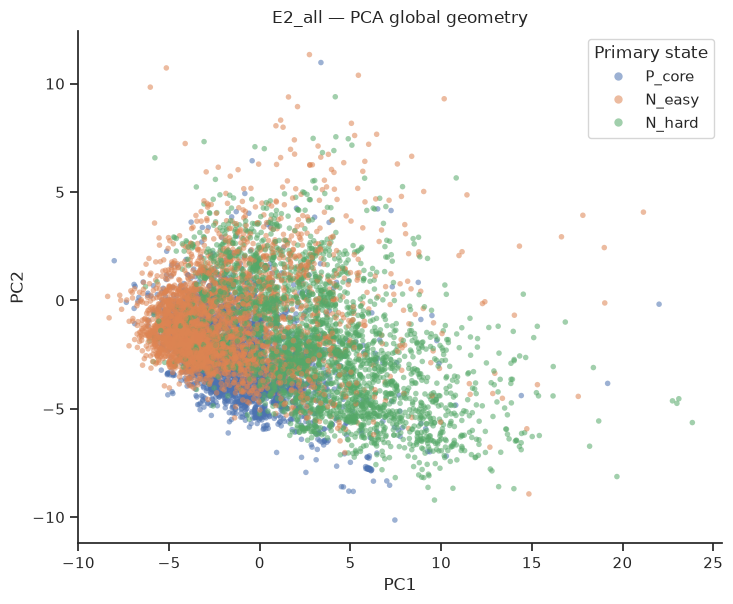

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_all.pdf


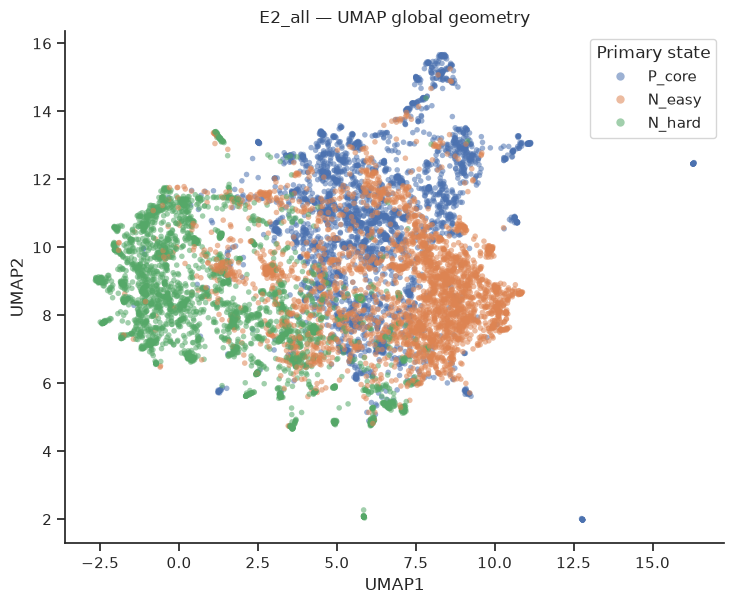

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_all.pdf


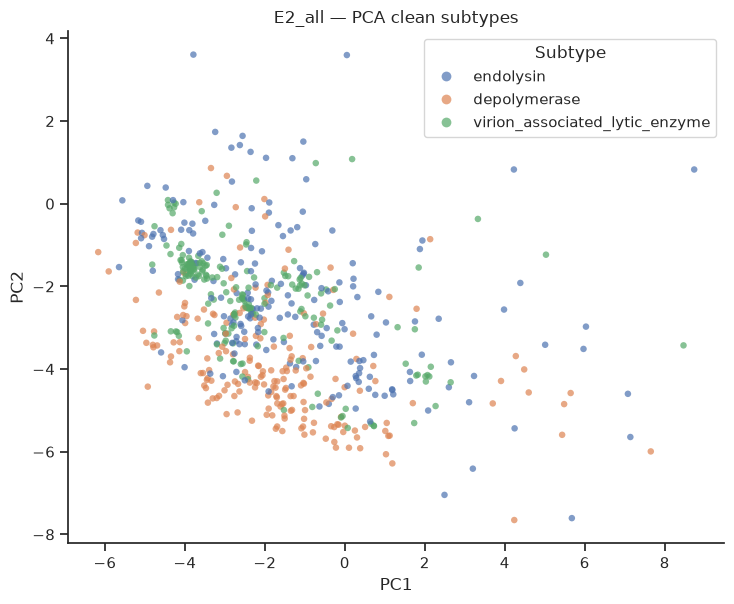

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_all.pdf


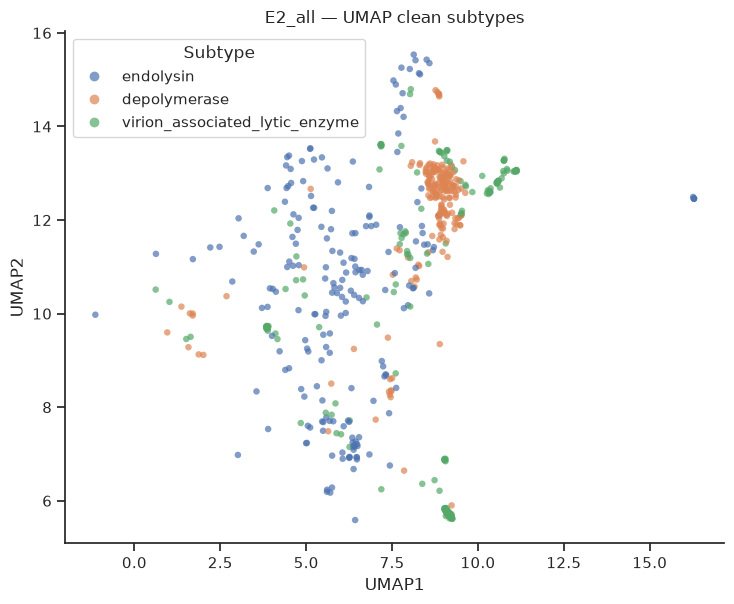

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E3_all.pdf


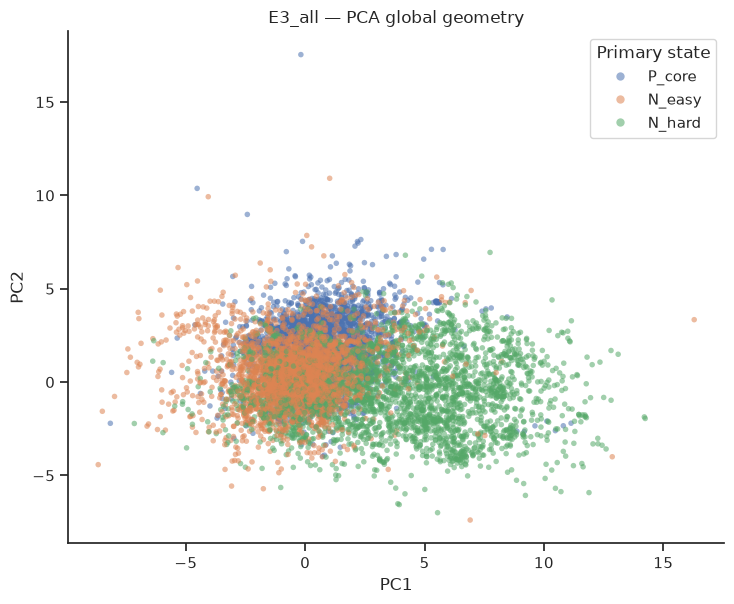

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E3_all.pdf


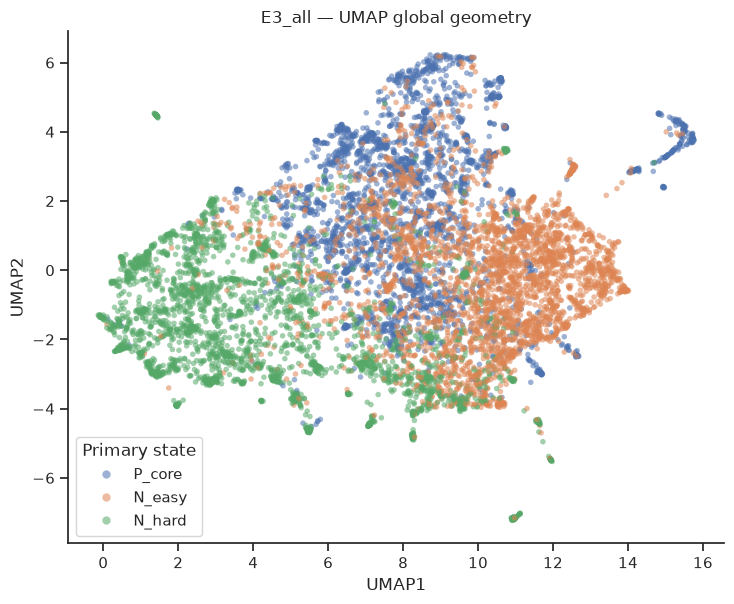

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E3_all.pdf


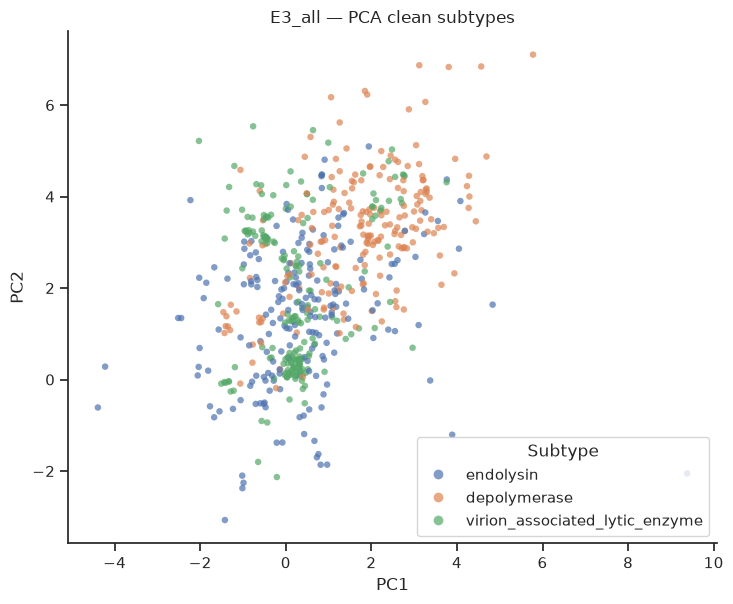

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E3_all.pdf


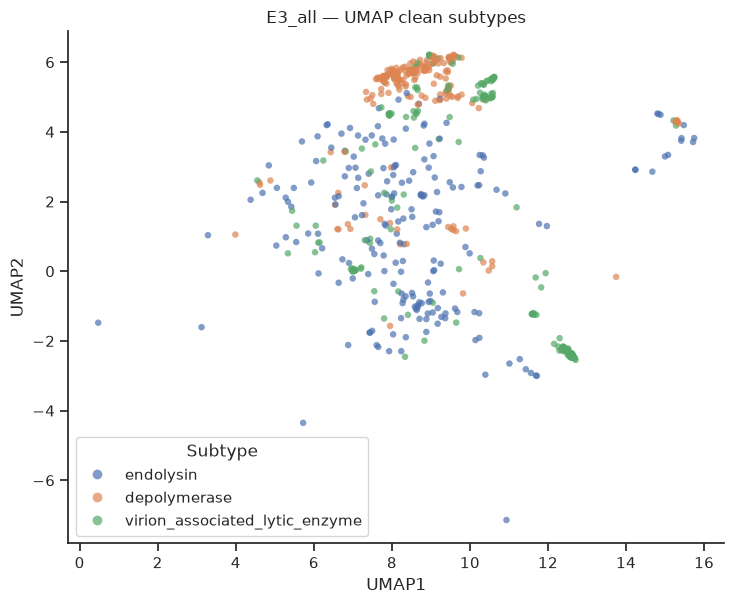

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_E3_all.pdf


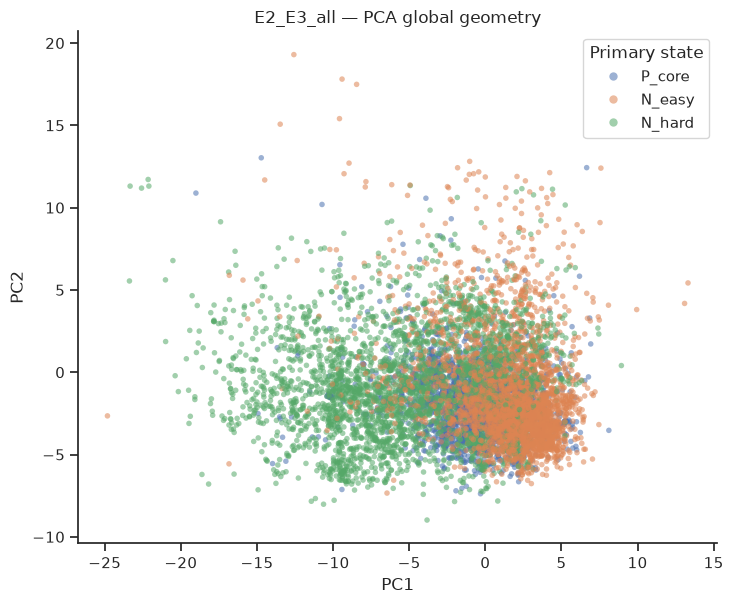

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_E3_all.pdf


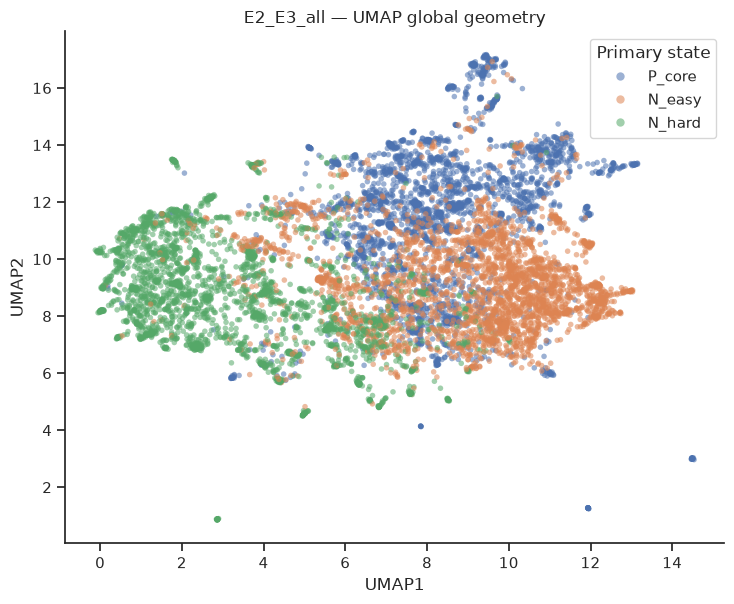

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_E3_all.pdf


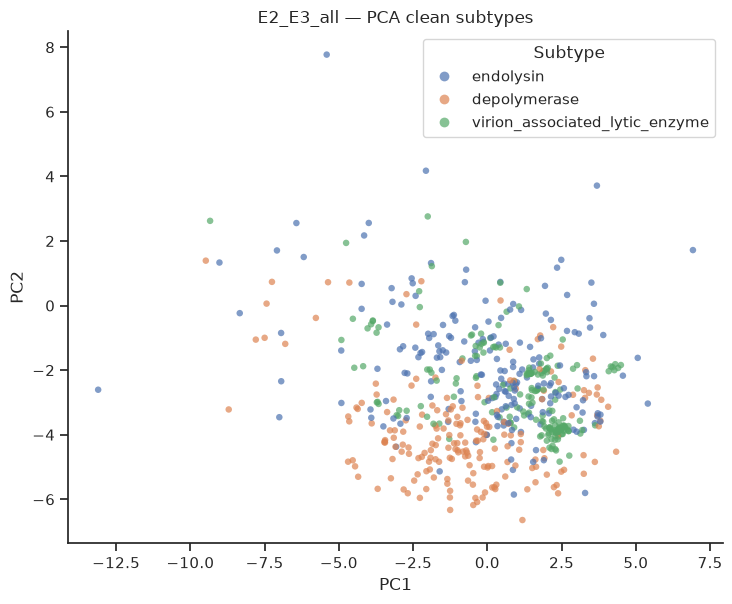

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_E3_all.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_E3_all.pdf


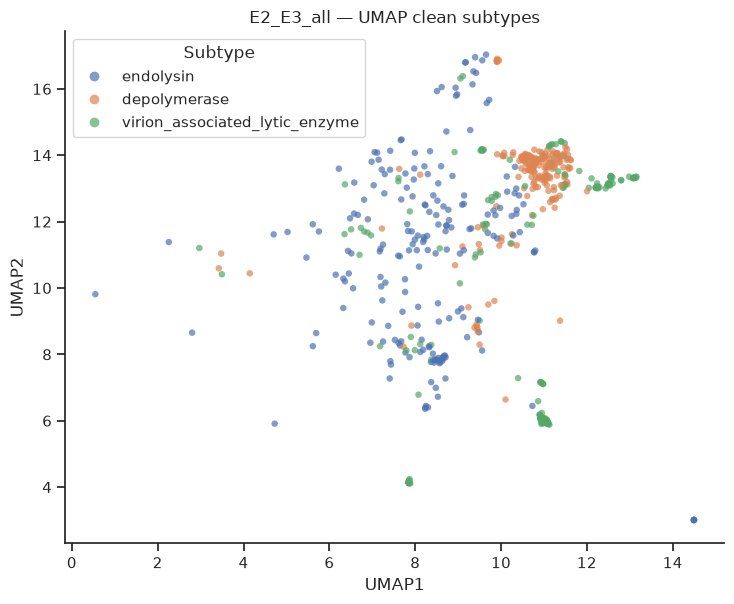

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_important.pdf


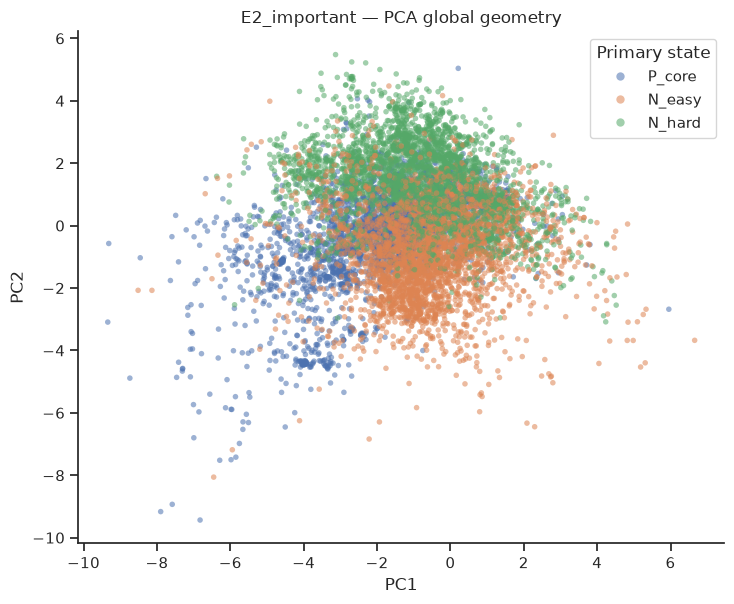

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_important.pdf


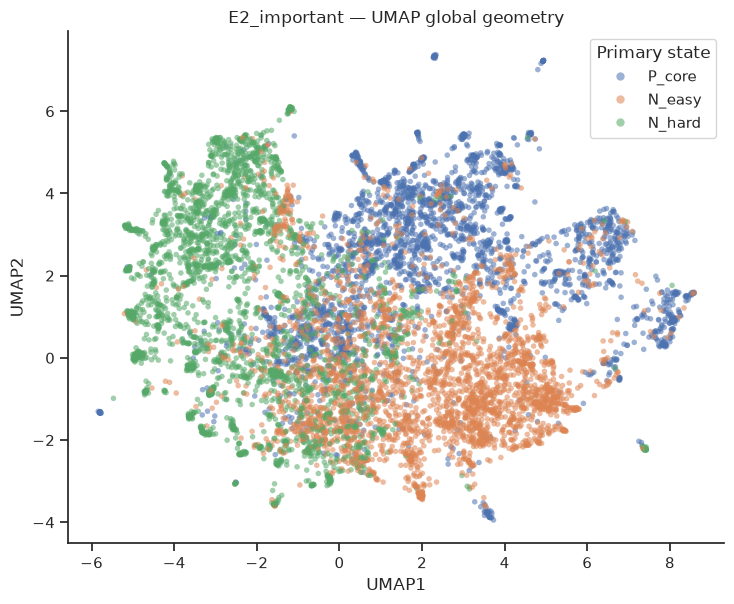

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_important.pdf


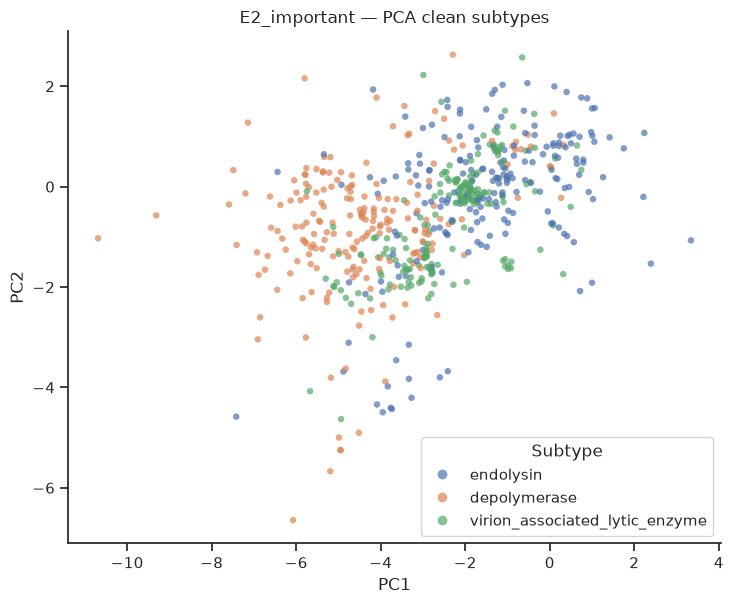

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_important.pdf


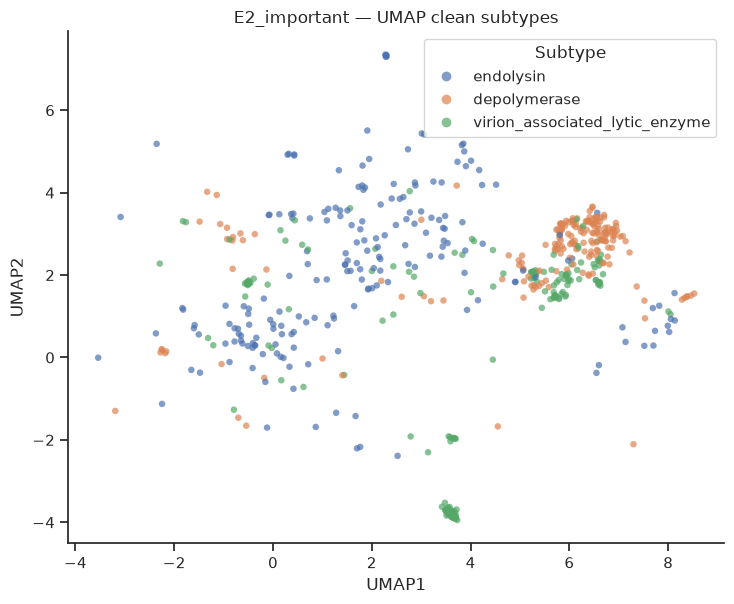

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E3_important.pdf


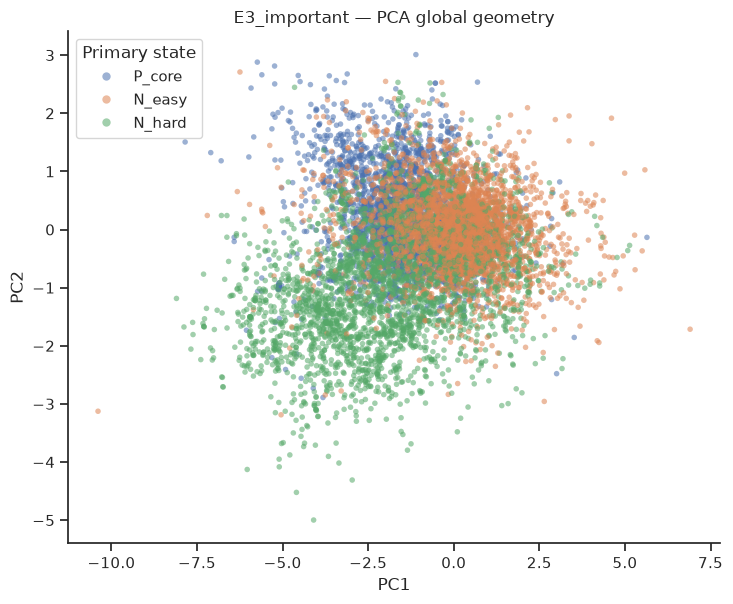

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E3_important.pdf


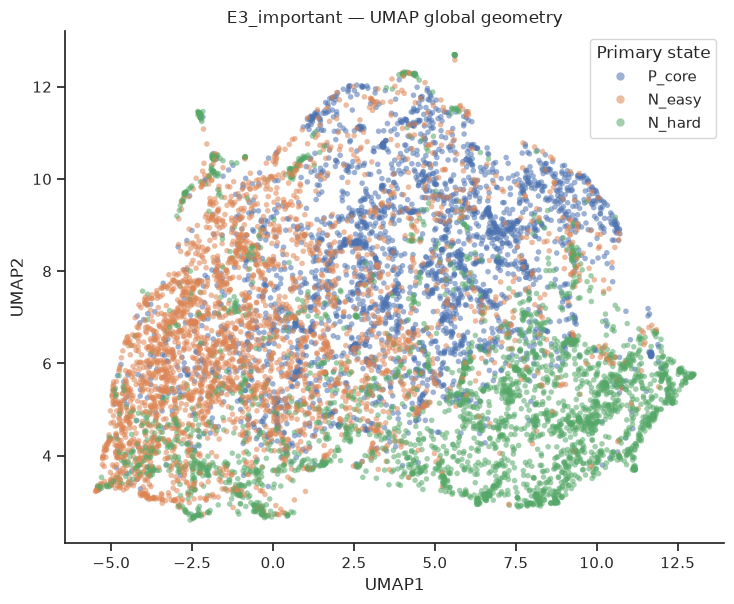

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E3_important.pdf


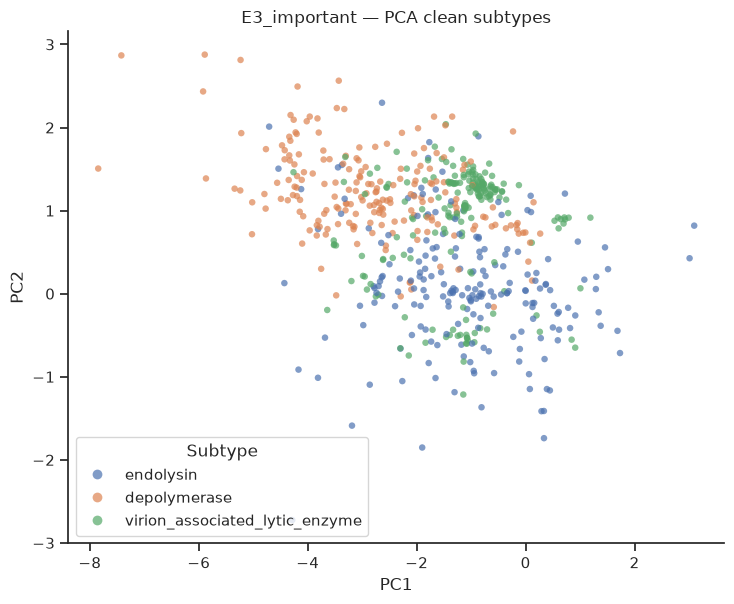

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E3_important.pdf


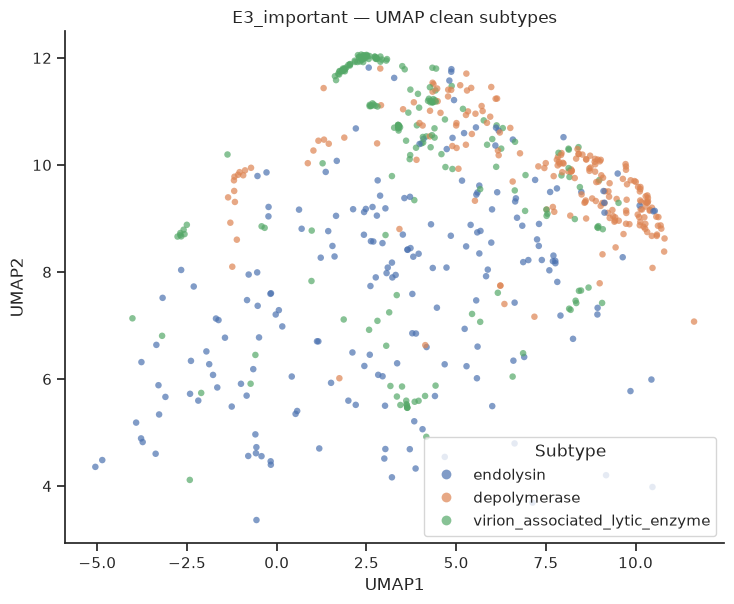

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_global_E2_E3_important.pdf


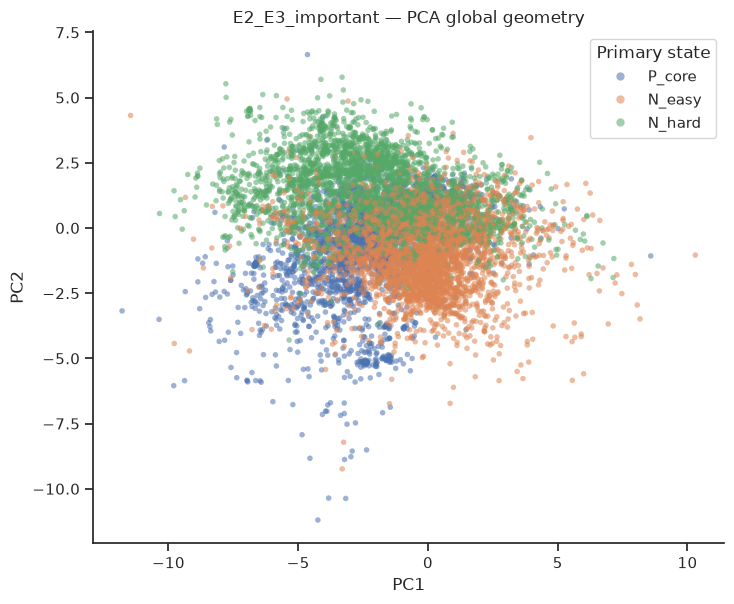

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_global_E2_E3_important.pdf


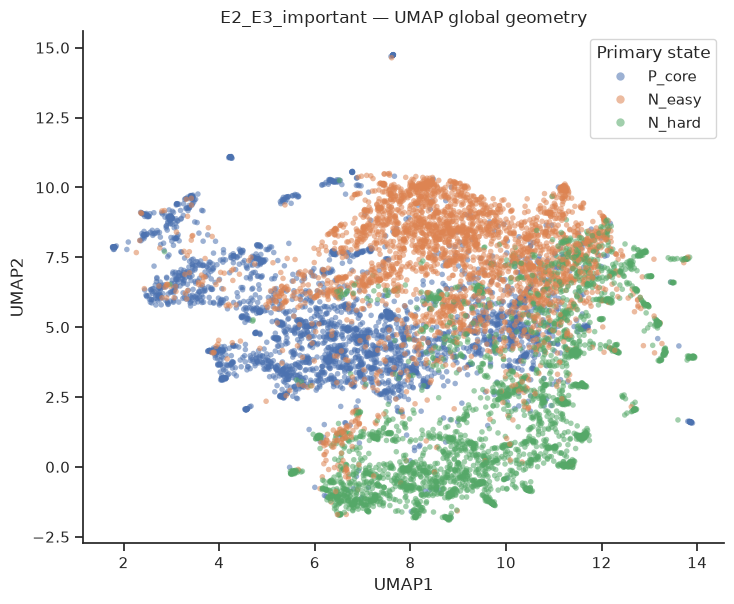

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_PCA_subtypes_E2_E3_important.pdf


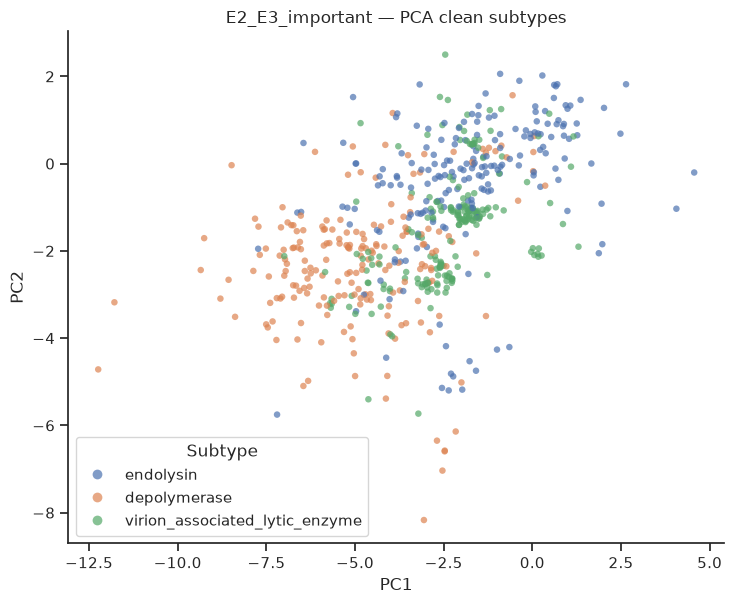

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_E3_important.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_UMAP_subtypes_E2_E3_important.pdf


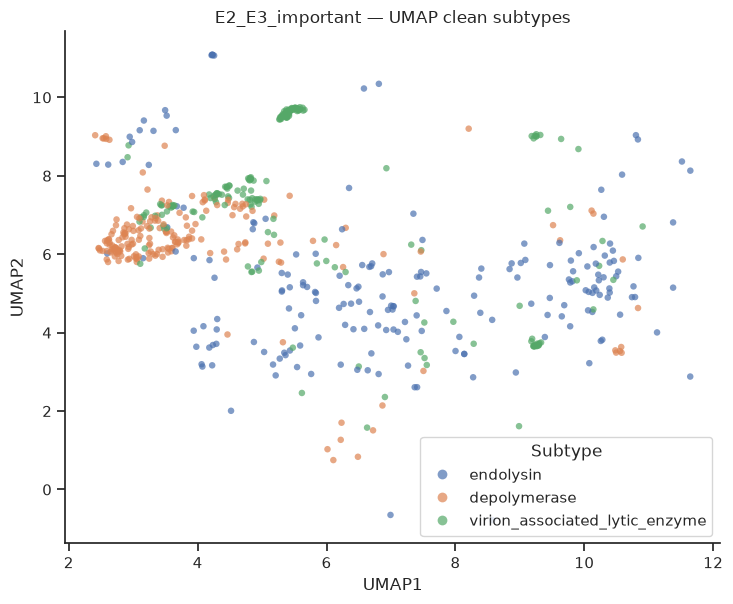

In [14]:
GLOBAL_HUE_ORDER = [
    "P_core",
    "N_easy",
    "N_hard",
]

SUBTYPE_HUE_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]


for feature_set_name in FEATURE_SETS:
    safe = safe_name(
        feature_set_name
    )

    pca_set = pca_coordinates.loc[
        pca_coordinates[
            "feature_set"
        ].eq(
            feature_set_name
        )
    ].copy()

    umap_set = umap_coordinates.loc[
        umap_coordinates[
            "feature_set"
        ].eq(
            feature_set_name
        )
    ].copy()

    # Global PCA
    global_pca = pca_set.loc[
        pca_set[
            "in_global_viz_sample"
        ]
        & pca_set[
            "sequence_state"
        ].isin(
            GLOBAL_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=global_pca,
        x="PC1",
        y="PC2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{feature_set_name} — PCA global geometry"
    )
    ax.legend(
        title="Primary state",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E4_PCA_global_{safe}",
    )

    plt.show()

    # Global UMAP
    global_umap = umap_set.loc[
        umap_set[
            "in_global_viz_sample"
        ]
        & umap_set[
            "sequence_state"
        ].isin(
            GLOBAL_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=global_umap,
        x="UMAP1",
        y="UMAP2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{feature_set_name} — UMAP global geometry"
    )
    ax.legend(
        title="Primary state",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E4_UMAP_global_{safe}",
    )

    plt.show()

    # Subtype PCA
    subtype_pca = pca_set.loc[
        pca_set[
            "in_subtype_viz_sample"
        ]
        & pca_set[
            "subtype_label"
        ].isin(
            SUBTYPE_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=subtype_pca,
        x="PC1",
        y="PC2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{feature_set_name} — PCA clean subtypes"
    )
    ax.legend(
        title="Subtype",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E4_PCA_subtypes_{safe}",
    )

    plt.show()

    # Subtype UMAP
    subtype_umap = umap_set.loc[
        umap_set[
            "in_subtype_viz_sample"
        ]
        & umap_set[
            "subtype_label"
        ].isin(
            SUBTYPE_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=subtype_umap,
        x="UMAP1",
        y="UMAP2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{feature_set_name} — UMAP clean subtypes"
    )
    ax.legend(
        title="Subtype",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E4_UMAP_subtypes_{safe}",
    )

    plt.show()

### Quantitative comparison of geometry views

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_silhouette_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_silhouette_global_three_state.pdf


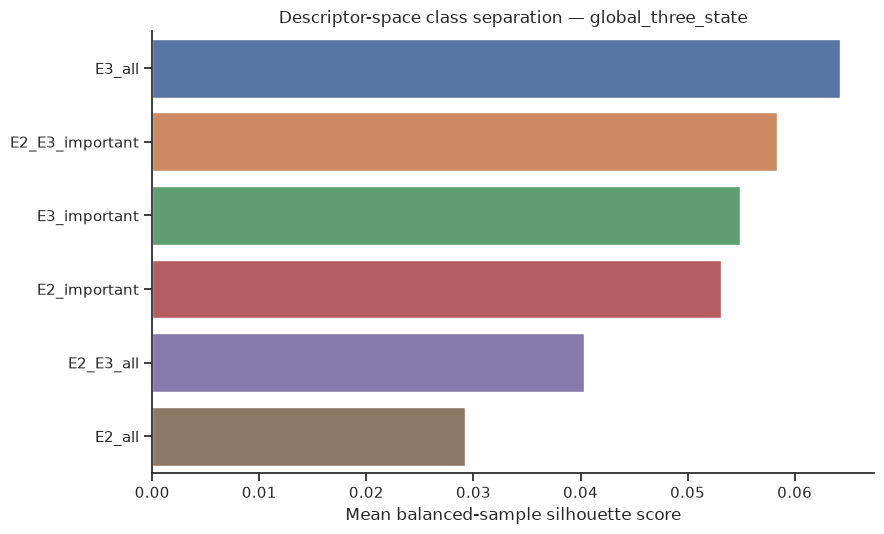

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_silhouette_global_binary.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_silhouette_global_binary.pdf


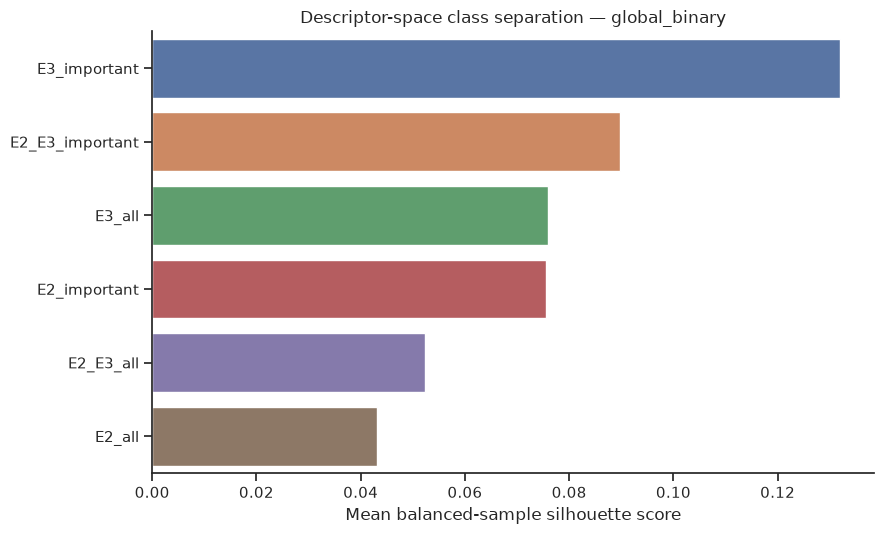

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_silhouette_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_silhouette_clean_subtypes.pdf


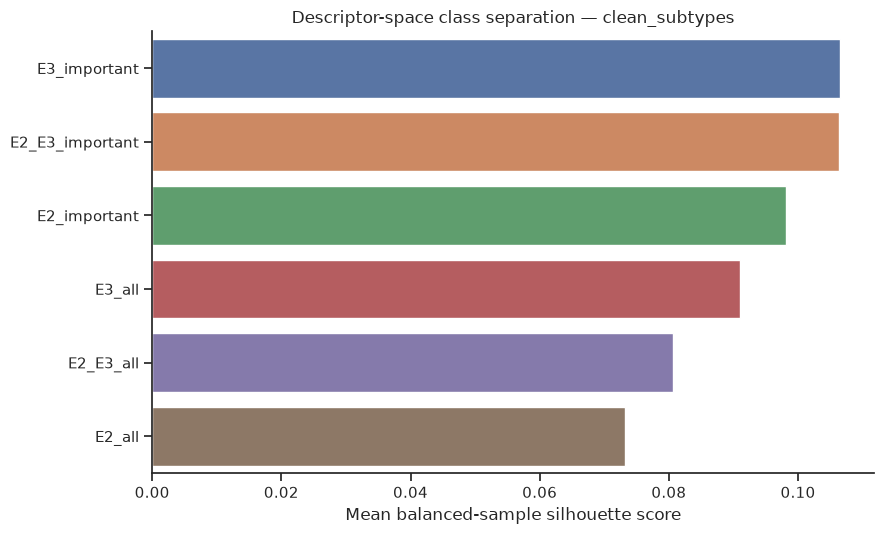

In [15]:
for scope_name in SCOPE_CONFIG:
    comparison = (
        geometry_repeated_summary.loc[
            geometry_repeated_summary[
                "scope"
            ].eq(
                scope_name
            )
            & geometry_repeated_summary[
                "metric"
            ].eq(
                "silhouette_score"
            )
        ]
        .sort_values(
            "mean",
            ascending=False,
        )
        .copy()
    )

    fig, ax = plt.subplots(
        figsize=(9.0, 5.5)
    )

    sns.barplot(
        data=comparison,
        y="feature_set",
        x="mean",
        hue="feature_set",
        dodge=False,
        legend=False,
        ax=ax,
    )

    ax.set_xlabel(
        "Mean balanced-sample silhouette score"
    )
    ax.set_ylabel("")
    ax.set_title(
        f"Descriptor-space class separation — {scope_name}"
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E4_geometry_silhouette_{safe_name(scope_name)}",
    )

    plt.show()

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_knn25_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_knn25_global_three_state.pdf


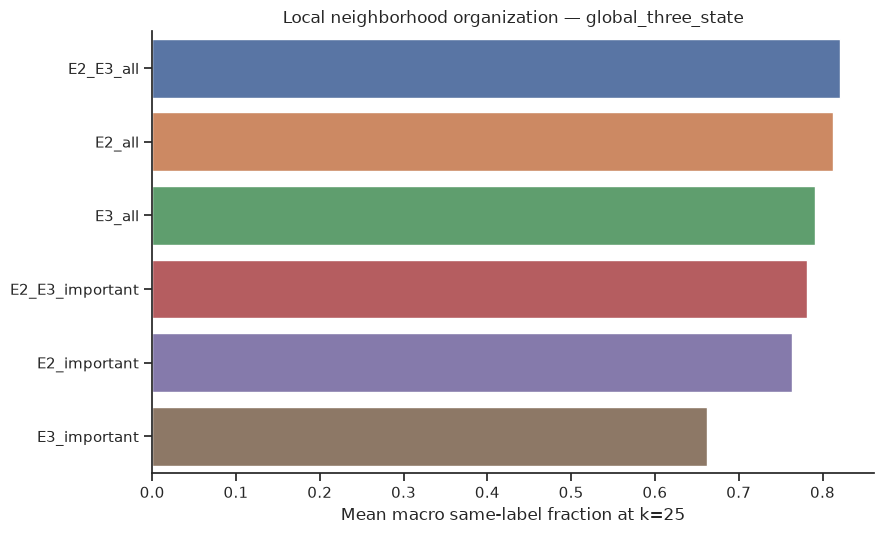

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_knn25_global_binary.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_knn25_global_binary.pdf


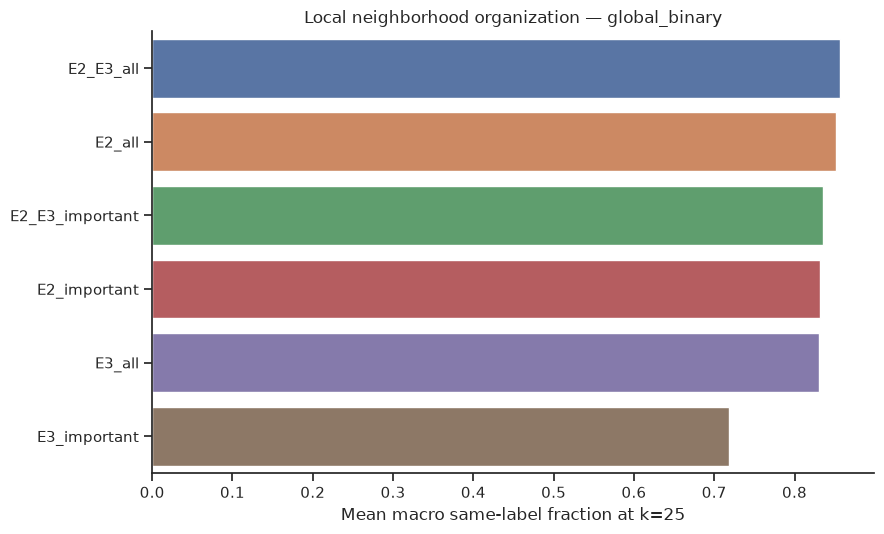

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_knn25_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/figures/E4_geometry_knn25_clean_subtypes.pdf


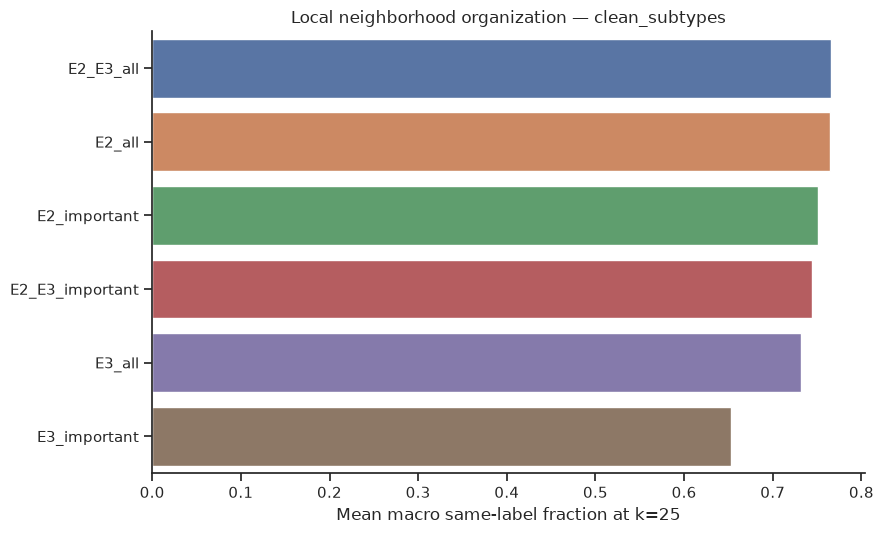

In [16]:
for scope_name in SCOPE_CONFIG:
    comparison = (
        geometry_repeated_summary.loc[
            geometry_repeated_summary[
                "scope"
            ].eq(
                scope_name
            )
            & geometry_repeated_summary[
                "metric"
            ].eq(
                "macro_knn_same_label_fraction"
            )
            & geometry_repeated_summary[
                "k"
            ].eq(25)
        ]
        .sort_values(
            "mean",
            ascending=False,
        )
        .copy()
    )

    fig, ax = plt.subplots(
        figsize=(9.0, 5.5)
    )

    sns.barplot(
        data=comparison,
        y="feature_set",
        x="mean",
        hue="feature_set",
        dodge=False,
        legend=False,
        ax=ax,
    )

    ax.set_xlabel(
        "Mean macro same-label fraction at k=25"
    )
    ax.set_ylabel("")
    ax.set_title(
        f"Local neighborhood organization — {scope_name}"
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E4_geometry_knn25_{safe_name(scope_name)}",
    )

    plt.show()

## 12. Final closure checks

In [17]:
assert len(E2_FROZEN_FEATURES) == 77
assert len(E3_FROZEN_FEATURES) == 27

assert len(E2_ALL_FEATURES) <= len(E2_FROZEN_FEATURES)
assert len(E3_ALL_FEATURES) <= len(E3_FROZEN_FEATURES)

assert len(E2_ALL_FEATURES) >= 2
assert len(E3_ALL_FEATURES) >= 2

assert len(FEATURE_SETS) == 6

assert set(FEATURE_SETS) == {
    "E2_all",
    "E3_all",
    "E2_E3_all",
    "E2_important",
    "E3_important",
    "E2_E3_important",
}

assert (
    len(FEATURE_SETS["E2_E3_all"])
    == len(E2_ALL_FEATURES)
    + len(E3_ALL_FEATURES)
)

assert (
    len(FEATURE_SETS["E2_E3_important"])
    == len(E2_IMPORTANT_FEATURES)
    + len(E3_IMPORTANT_FEATURES)
)

# No geometry feature may contain missing/non-finite values.
assert not analysis[
    E2_ALL_FEATURES + E3_ALL_FEATURES
].isna().any().any()

# No excluded feature may leak back into a geometry set.
excluded_features = set(
    feature_eligibility.loc[
        ~feature_eligibility["geometry_eligible"],
        "feature",
    ]
)

for feature_set_name, features in FEATURE_SETS.items():
    leaked = excluded_features.intersection(features)

    if leaked:
        raise RuntimeError(
            f"{feature_set_name} contains geometry-ineligible features: "
            + ", ".join(sorted(leaked))
        )

assert not pca_coordinates.empty
assert not umap_coordinates.empty
assert not roxy_geometry_repeats.empty
assert not roxy_geometry_summary.empty
assert not roxy_neighborhood_repeats.empty
assert not roxy_neighborhoods.empty

assert set(
    pca_coordinates["feature_set"]
) == set(FEATURE_SETS)

assert set(
    umap_coordinates["feature_set"]
) == set(FEATURE_SETS)

assert set(
    roxy_geometry_repeats["feature_set"]
) == set(FEATURE_SETS)

assert set(
    roxy_geometry_summary["feature_set"]
) == set(FEATURE_SETS)

assert set(
    roxy_geometry_repeats["scope"]
) == set(SCOPE_CONFIG)

assert set(
    roxy_neighborhood_repeats["k"]
) == set(NEIGHBOR_K_VALUES)

assert set(
    roxy_neighborhoods["k"]
) == set(NEIGHBOR_K_VALUES)

required_outputs = [
    FEATURE_ELIGIBILITY_PATH,
    FEATURE_SETS_PATH,
    IMPORTANCE_PATH,
    SAMPLE_MANIFEST_PATH,
    PCA_COORDINATES_PATH,
    UMAP_COORDINATES_PATH,
    PCA_VARIANCE_PATH,
    PCA_LOADINGS_PATH,
    GEOMETRY_REPEATS_PATH,
    GEOMETRY_SUMMARY_PATH,
    NEIGHBORHOOD_REPEATS_PATH,
    NEIGHBORHOODS_PATH,
]

for path in required_outputs:
    assert path.is_file(), (
        f"Missing E4 output: {path}"
    )

metadata = {
    "e0_rows": int(len(e0)),
    "e2_frozen_feature_count": int(
        len(E2_FROZEN_FEATURES)
    ),
    "e2_geometry_eligible_feature_count": int(
        len(E2_ALL_FEATURES)
    ),
    "e2_geometry_excluded_feature_count": int(
        len(E2_FROZEN_FEATURES)
        - len(E2_ALL_FEATURES)
    ),
    "e3_frozen_feature_count": int(
        len(E3_FROZEN_FEATURES)
    ),
    "e3_geometry_eligible_feature_count": int(
        len(E3_ALL_FEATURES)
    ),
    "e3_geometry_excluded_feature_count": int(
        len(E3_FROZEN_FEATURES)
        - len(E3_ALL_FEATURES)
    ),
    "e2_important_feature_count": int(
        len(E2_IMPORTANT_FEATURES)
    ),
    "e3_important_feature_count": int(
        len(E3_IMPORTANT_FEATURES)
    ),
    "important_selection_quantile": 0.75,
    "missing_value_policy": (
        "exclude descriptor from multivariate geometry; "
        "do not impute and do not delete sequences"
    ),
    "feature_sets": {
        name: len(features)
        for name, features in FEATURE_SETS.items()
    },
    "pca_components_requested": PCA_COMPONENTS,
    "umap_n_neighbors": UMAP_N_NEIGHBORS,
    "umap_min_dist": UMAP_MIN_DIST,
    "neighbor_k_values": NEIGHBOR_K_VALUES,
    "global_metric_repeats": GLOBAL_METRIC_REPEATS,
    "subtype_metric_repeats": SUBTYPE_METRIC_REPEATS,
    "random_seed": RANDOM_SEED,
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("=" * 72)
print(
    "PASS — E4 descriptor-space geometry completed."
)
print("=" * 72)
print()
print(f"Feature eligibility    : {FEATURE_ELIGIBILITY_PATH}")
print(f"Feature sets           : {FEATURE_SETS_PATH}")
print(f"Feature importance     : {IMPORTANCE_PATH}")
print(f"Sample manifest        : {SAMPLE_MANIFEST_PATH}")
print(f"PCA coordinates        : {PCA_COORDINATES_PATH}")
print(f"UMAP coordinates       : {UMAP_COORDINATES_PATH}")
print(f"PCA variance           : {PCA_VARIANCE_PATH}")
print(f"PCA loadings           : {PCA_LOADINGS_PATH}")
print(f"Geometry raw repeats   : {GEOMETRY_REPEATS_PATH}")
print(f"Geometry summary       : {GEOMETRY_SUMMARY_PATH}")
print(f"Neighborhood raw       : {NEIGHBORHOOD_REPEATS_PATH}")
print(f"Neighborhood summary   : {NEIGHBORHOODS_PATH}")
print(f"Metadata               : {METADATA_PATH}")
print(f"Figures                : {FIGURE_DIR}")


PASS — E4 descriptor-space geometry completed.

Feature eligibility    : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_geometry_feature_eligibility.tsv
Feature sets           : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_geometry_feature_sets.tsv
Feature importance     : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_geometry_feature_importance.tsv
Sample manifest        : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_geometry_samples.tsv
PCA coordinates        : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_pca_coordinates.tsv
UMAP coordinates       : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E4/roxy_umap_coordinates.tsv
PCA variance           : /home/david/Desktop/colabs/inta_proj